ML Assignment -1

Dataset: Titanic Dataset (titanic_data_updated.csv)

Total Marks: 100

Email: raihanhabib2003811@gmail.com

Name: Raihan Habib Akash

Exam Instructions :
- প্রথমে একটি Google Colab ফাইল খুলবে , এরপর প্রথম cell এ নিজের নাম এবং কোর্সে registration করা ইমেইল দিবে
- Question wise numbering করে Text cell রাখবে এবং এর নিচে Code cell থাকবে, চেষ্টা করবে একটি code cell এ একটি question উত্তর দেয়ার
- Google colab এর মধ্যে কোডগুলো করবে
- এবং সেই ফাইলটি ‘Anyone with the link’ & ‘View’ Access দিয়ে ফাইলটির Shareble Link টি সাবমিট করবে।


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

In [3]:
df = pd.read_csv("/content/titanic_data_updated.csv")

# Question 1 (10 Marks)
Load the Titanic dataset and display:
- Dataset shape
- First 10 rows
- 5 random samples

In [8]:
print("Df shape is: ",df.shape)
print()

print(df.head(10))
print()

df.sample(5)

Df shape is:  (891, 12)

   PassengerId Survived  Pclass  \
0            1       no   third   
1            2      yes   first   
2            3      yes   third   
3            4      yes   first   
4            5       no   third   
5            6       no   third   
6            7       no   first   
7            8       no   third   
8            9      yes   third   
9           10      yes  second   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   
5                                   Moran, Mr. James    male   NaN      0   
6                            McCarthy, Mr. Timothy

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,no,third,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
375,376,yes,first,"Meyer, Mrs. Edgar Joseph (Leila Saks)",female,NaN,1,0,PC 17604,82.1708,NaN,C
689,690,yes,first,"Madill, Miss. Georgette Alexandra",female,15.0,0,1,24160,211.3375,B5,S
552,553,no,third,"O'Brien, Mr. Timothy",male,NaN,0,0,330979,7.8292,NaN,Q
490,491,no,third,"Hagland, Mr. Konrad Mathias Reiersen",male,NaN,1,0,65304,19.9667,NaN,S


# Question 2 (10 Marks)
Perform feature screening on the Titanic dataset by:
- Finding total missing values
- Finding duplicate rows
- Removing duplicate rows permanently

In [20]:
print("Total missing values are ", df.isnull().sum().sum())
print()

print("Total duplicate rows are ", df.duplicated().sum())
print()

df.drop_duplicates(inplace=True)

Total missing values are  866

Total duplicate rows are  0



# Question 3 (10 Marks)
Perform statistical profiling of the Titanic dataset and display:
- Dataset information
- Statistical summary of numerical columns

Also write 2 observations from the output.

In [23]:
print(df.info())
print()

df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    object 
 2   Pclass       891 non-null    object 
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(3), object(7)
memory usage: 83.7+ KB
None



,PassengerId,Age,SibSp,Parch,Fare
count,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,29.699118,0.523008,0.381594,32.204208
std,257.353842,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,38.000000,1.000000,0.000000,31.000000
max,891.000000,80.000000,8.000000,6.000000,512.329200


1. Cabin Feature have the most null values. We can't impute it. So I would like to drop it from the Df.
2. Age & Embarked have some null values. Age is Numerical datatype. So we can use mean or median. And Embarked is Categorical datatype. So we can use Mode or Constant to impute the null values.

# Question 4 (10 Marks)
Perform univariate categorical analysis on the Survived column by:
- Creating a countplot
- Calculating percentage distribution
- Creating a pie chart

Write 2 insights from the analysis.

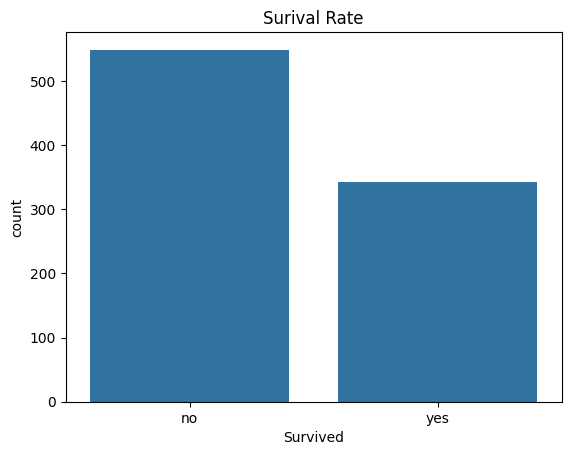

In [67]:
plt.title("Surival Rate")
sns.countplot(data = df, x='Survived')
plt.show()

In [37]:
(df['Survived'].value_counts() / len(df) ) * 100

,count
Survived,
no,61.616162
yes,38.383838


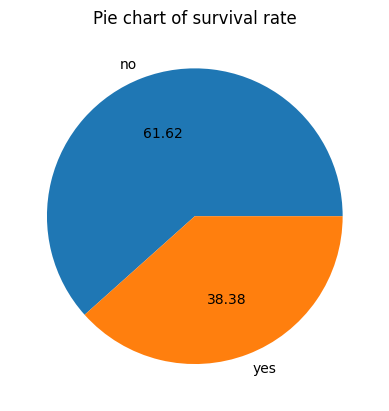

In [68]:
survived_counts = df['Survived'].value_counts()

survived_labels = df['Survived'].unique()

plt.pie(survived_counts, labels=survived_labels, autopct="%1.2f")
plt.title('Pie chart of survival rate')
plt.show()

1. 500+ people could not survived.
2. Only 38% people survived.

# Question 5 (10 Marks)
Perform univariate numerical analysis on the Age column by:
- Creating a histogram
- Creating a KDE plot

Write 2 observations from the plots.

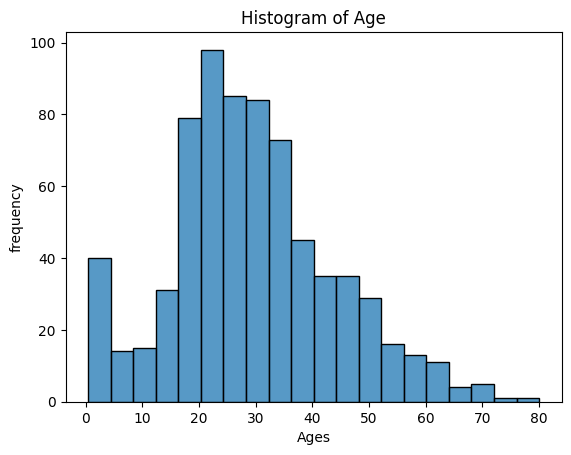

In [59]:
sns.histplot(df['Age'])

plt.title('Histogram of Age')
plt.xlabel('Ages')
plt.ylabel('frequency')

plt.show()

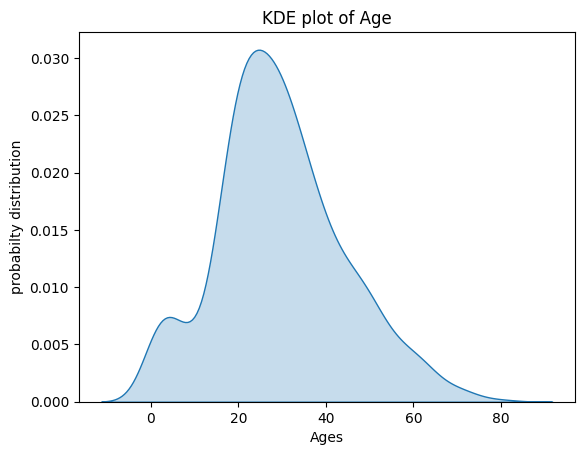

In [69]:
sns.kdeplot(data=df, x="Age", fill=True)
plt.title('KDE plot of Age')
plt.xlabel('Ages')
plt.ylabel('probabilty distribution')

plt.show()

1. histogram: Maximum peoples age were 15-40
2. Kde Plot: There are some outlayers in Age 80.

# Question 6 (10 Marks)
Perform multivariate analysis between Sex and Survived using a countplot with hue.

Also calculate normalized survival ratios using groupby().

Write 2 insights from the analysis.

Sex     Survived
female  yes         0.742038
        no          0.257962
male    no          0.811092
        yes         0.188908
Name: proportion, dtype: float64


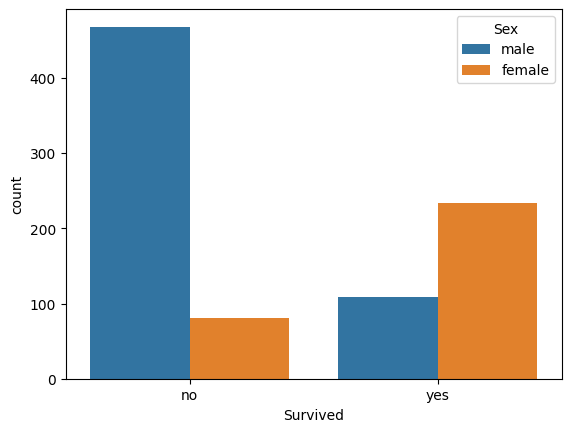

In [89]:
sns.countplot(data=df, x='Survived', hue='Sex')

print(df.groupby('Sex')['Survived'].value_counts(normalize=True))

1. Maximum Man could not survive.
2. Maximum Woman survived.

# Question 7 (10 Marks)

Create a barplot showing the relationship between Pclass and Fare.

Write 2 observations from the visualization.

<Axes: xlabel='Pclass', ylabel='Fare'>

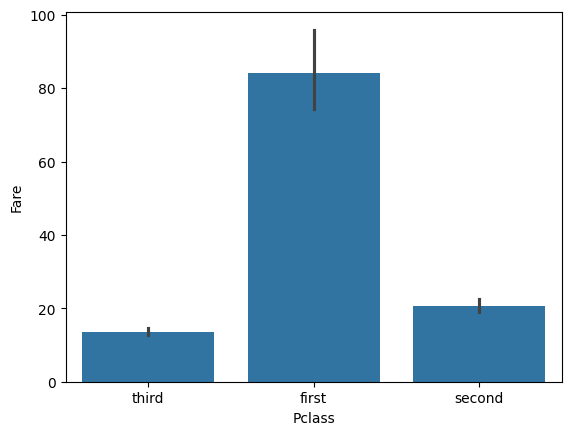

In [74]:
sns.barplot(x=df['Pclass'],y=df['Fare'])

1. Maximum Avg Fare was given from First Pclass.
2. Third And Second Pclass avg sum is less than First Pclass avg

# Question 8 (10 Marks)

Create a KDE plot to compare the Age distribution of survived and non-survived passengers.

Write 2 insights from the graph.

<Axes: xlabel='Age', ylabel='Density'>

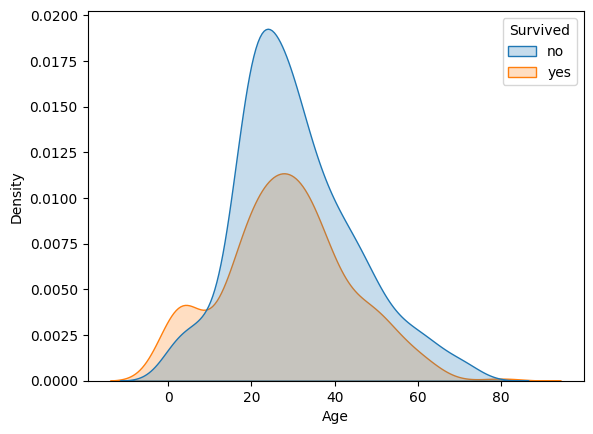

In [76]:
sns.kdeplot(data =df , x ='Age', hue='Survived', fill=True)

1. Kids were survived Max.
2. None Old people could survived.

# Question 9 (10 Marks)
Perform feature engineering and train-test split by:
- Dropping PassengerId, Name, and Ticket columns
- Separating features (X) and target (y)
- Splitting the dataset using test_size=0.2 and random_state=42

Display the shapes of train and test datasets.

In [90]:
data = df.drop(['PassengerId','Name','Ticket'], axis=1)

X = data.drop(['Survived'], axis=1)
y = data['Survived']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

print("X_train shape: ", X_train.shape)
print("X_test shape: ", X_test.shape)
print("y_train shape: ", y_train.shape)
print("y_test shape: ", y_test.shape)

X_train shape:  (712, 8)
X_test shape:  (179, 8)
y_train shape:  (712,)
y_test shape:  (179,)


# Question 10 (10 Marks)
Handle missing values in the Titanic dataset by:
- Imputing missing Age values using SimpleImputer with mean strategy
- Imputing missing Embarked values using most frequent strategy
- Imputing missing Cabin values using constant strategy with "Missing"

Finally, check whether any missing values remain.

In [91]:
age_mean_imputer = SimpleImputer(missing_values=np.nan, strategy='mean')
age_mean_imputer.fit(X_train[['Age']])
X_train['Age'] = age_mean_imputer.transform(X_train[['Age']]).ravel()
X_test['Age'] = age_mean_imputer.transform(X_test[['Age']]).ravel()

embarked_freq_imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
embarked_freq_imputer.fit(X_train[['Embarked']])
X_train['Embarked'] = embarked_freq_imputer.transform(X_train[['Embarked']]).ravel()
X_test['Embarked'] = embarked_freq_imputer.transform(X_test[['Embarked']]).ravel()

cabin_constan_imputer = SimpleImputer(missing_values=np.nan, strategy='constant', fill_value='Missing')
cabin_constan_imputer.fit(X_train[['Cabin']])
X_train['Cabin'] = cabin_constan_imputer.transform(X_train[['Cabin']]).ravel()
X_test['Cabin'] = cabin_constan_imputer.transform(X_test[['Cabin']]).ravel()

print(X_test.isnull().sum())
X_train.isnull().sum()

Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Cabin       0
Embarked    0
dtype: int64


,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Cabin,0
Embarked,0
